Imports and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#F9F9F9',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

BLUE   = '#1B4F8A'
RED    = '#C0392B'
GREEN  = '#27AE60'
ORANGE = '#E67E22'
GREY   = '#95A5A6'
PURPLE = '#8E44AD'

from pathlib import Path
from google.colab import files

FIGURES   = Path('/content/figures')
PROCESSED = Path('/content/processed')
FIGURES.mkdir(exist_ok=True)
PROCESSED.mkdir(exist_ok=True)

print("Upload hillstrom_clean.csv")
uploaded = files.upload()

df = pd.read_csv('hillstrom_clean.csv')
print(f"Loaded: {len(df):,} rows")


Upload hillstrom_clean.csv


Saving hillstrom_clean.csv to hillstrom_clean.csv
Loaded: 64,000 rows


 The fundamental problem of causal inference

In [2]:
print("THE FUNDAMENTAL PROBLEM OF CAUSAL INFERENCE")
print("=" * 55)
print("""
For every customer, we want to know:
  Y(1) = outcome IF they received the email
  Y(0) = outcome IF they did NOT receive the email
  Uplift = Y(1) - Y(0)

The problem: we only ever observe ONE of these.
A customer either got the email or they didn't.
We never see the counterfactual.

This is why we need a MODEL — to impute the unobserved potential outcome.

The four customer types (Persuadables, Sure Things, etc.) are defined
by the JOINT values of Y(1) and Y(0), which we can never directly observe:

  Y(1)=1, Y(0)=0 → Persuadable    (email causes conversion)
  Y(1)=1, Y(0)=1 → Sure Thing     (converts regardless)
  Y(1)=0, Y(0)=0 → Lost Cause     (never converts)
  Y(1)=0, Y(0)=1 → Sleeping Dog   (email PREVENTS conversion)

Our uplift model estimates E[Y(1) - Y(0) | X] for each customer.
""")

# Feature set — pre-treatment only
FEATURES = ['recency', 'history', 'mens', 'womens', 'zip_code_enc', 'newbie', 'channel_enc']
OUTCOME   = 'visit'        # primary outcome: website visit within 2 weeks
TREATMENT = 'treatment_any'

print(f"Features : {FEATURES}")
print(f"Outcome  : {OUTCOME}  (visit rate = {df[OUTCOME].mean()*100:.1f}%)")
print(f"Treatment: {TREATMENT}  (1 = received any email)")
print()
print(f"Treatment group : {df[TREATMENT].sum():,} customers  ({df[TREATMENT].mean()*100:.0f}%)")
print(f"Control group   : {(1-df[TREATMENT]).sum():,} customers  ({(1-df[TREATMENT]).mean()*100:.0f}%)")


THE FUNDAMENTAL PROBLEM OF CAUSAL INFERENCE

For every customer, we want to know:
  Y(1) = outcome IF they received the email
  Y(0) = outcome IF they did NOT receive the email
  Uplift = Y(1) - Y(0)

The problem: we only ever observe ONE of these.
A customer either got the email or they didn't.
We never see the counterfactual.

This is why we need a MODEL — to impute the unobserved potential outcome.

The four customer types (Persuadables, Sure Things, etc.) are defined
by the JOINT values of Y(1) and Y(0), which we can never directly observe:

  Y(1)=1, Y(0)=0 → Persuadable    (email causes conversion)
  Y(1)=1, Y(0)=1 → Sure Thing     (converts regardless)
  Y(1)=0, Y(0)=0 → Lost Cause     (never converts)
  Y(1)=0, Y(0)=1 → Sleeping Dog   (email PREVENTS conversion)

Our uplift model estimates E[Y(1) - Y(0) | X] for each customer.

Features : ['recency', 'history', 'mens', 'womens', 'zip_code_enc', 'newbie', 'channel_enc']
Outcome  : visit  (visit rate = 14.7%)
Treatment: treatment

Train/test split

In [3]:
X = df[FEATURES].copy()
y = df[OUTCOME].copy()
t = df[TREATMENT].copy()

# Stratify on treatment to preserve group balance in both splits
X_train, X_test, y_train, y_test, t_train, t_test = train_test_split(
    X, y, t,
    test_size=0.30,
    random_state=42,
    stratify=t
)

print(f"Training set : {len(X_train):,}  (treatment={t_train.mean()*100:.0f}%)")
print(f"Test set     : {len(X_test):,}   (treatment={t_test.mean()*100:.0f}%)")
print()
print("Why stratify on treatment?")
print("We must preserve the treatment/control ratio in both splits.")
print("If the test set had more treated customers than the training split,")
print("our Qini curve evaluation would be invalid.")


Training set : 44,800  (treatment=67%)
Test set     : 19,200   (treatment=67%)

Why stratify on treatment?
We must preserve the treatment/control ratio in both splits.
If the test set had more treated customers than the training split,
our Qini curve evaluation would be invalid.


T-Learner (Two-Model Approach)

In [4]:
print("T-LEARNER: Train separate models for treatment and control groups")
print("=" * 60)
print("""
Algorithm:
  1. Train model_control on CONTROL customers only → learns P(Y=1 | X, T=0)
  2. Train model_treat   on TREATMENT customers only → learns P(Y=1 | X, T=1)
  3. For any customer: uplift = model_treat.predict(X) - model_control.predict(X)

The uplift score is the estimated causal effect of treatment for that individual.
""")

# Split training data by treatment
ctrl_mask  = t_train == 0
treat_mask = t_train == 1

X_ctrl_train  = X_train[ctrl_mask];  y_ctrl_train  = y_train[ctrl_mask]
X_treat_train = X_train[treat_mask]; y_treat_train = y_train[treat_mask]

print(f"Control training set  : {len(X_ctrl_train):,} customers  "
      f"(conversion rate: {y_ctrl_train.mean()*100:.1f}%)")
print(f"Treatment training set: {len(X_treat_train):,} customers  "
      f"(conversion rate: {y_treat_train.mean()*100:.1f}%)")
print()

# Train both models
model_ctrl = RandomForestClassifier(
    n_estimators=200, max_depth=6, min_samples_leaf=50,
    random_state=42, n_jobs=-1
)
model_treat = RandomForestClassifier(
    n_estimators=200, max_depth=6, min_samples_leaf=50,
    random_state=42, n_jobs=-1
)

model_ctrl.fit(X_ctrl_train,  y_ctrl_train)
model_treat.fit(X_treat_train, y_treat_train)

# Predict on test set
p_ctrl_t  = model_ctrl.predict_proba(X_test)[:, 1]   # P(Y=1 | X, T=0)
p_treat_t = model_treat.predict_proba(X_test)[:, 1]  # P(Y=1 | X, T=1)
uplift_t  = p_treat_t - p_ctrl_t                      # individual uplift estimate

print(f"T-Learner uplift distribution (test set):")
print(f"  Mean   : {uplift_t.mean():.4f}")
print(f"  Std    : {uplift_t.std():.4f}")
print(f"  Min    : {uplift_t.min():.4f}")
print(f"  Max    : {uplift_t.max():.4f}")
print(f"  % positive (persuadable signal) : {(uplift_t > 0).mean()*100:.1f}%")


T-LEARNER: Train separate models for treatment and control groups

Algorithm:
  1. Train model_control on CONTROL customers only → learns P(Y=1 | X, T=0)
  2. Train model_treat   on TREATMENT customers only → learns P(Y=1 | X, T=1)
  3. For any customer: uplift = model_treat.predict(X) - model_control.predict(X)

The uplift score is the estimated causal effect of treatment for that individual.

Control training set  : 14,914 customers  (conversion rate: 10.4%)
Treatment training set: 29,886 customers  (conversion rate: 16.8%)

T-Learner uplift distribution (test set):
  Mean   : 0.0634
  Std    : 0.0247
  Min    : -0.0114
  Max    : 0.1667
  % positive (persuadable signal) : 99.9%


S-Learner (Single-Model Approach)

In [5]:
print("S-LEARNER: One model, treatment indicator as a feature")
print("=" * 60)
print("""
Algorithm:
  1. Add treatment indicator T as an extra feature
  2. Train ONE model on all customers
  3. Predict twice: once with T=1, once with T=0
  4. Uplift = prediction(X, T=1) - prediction(X, T=0)

Weakness vs T-Learner: the single model may learn to IGNORE treatment
if its signal is weak relative to other features — it can shrink the
uplift toward zero. T-Learner forces the model to learn group-specific
response functions.
""")

X_train_s = X_train.copy()
X_test_s  = X_test.copy()
X_train_s['treatment'] = t_train.values
X_test_s['treatment']  = t_test.values

model_s = RandomForestClassifier(
    n_estimators=200, max_depth=6, min_samples_leaf=50,
    random_state=42, n_jobs=-1
)
model_s.fit(X_train_s, y_train)

# Score each customer twice — once as treated, once as control
X_test_as_treat = X_test.copy(); X_test_as_treat['treatment'] = 1
X_test_as_ctrl  = X_test.copy(); X_test_as_ctrl['treatment']  = 0

uplift_s = (model_s.predict_proba(X_test_as_treat)[:, 1]
          - model_s.predict_proba(X_test_as_ctrl)[:, 1])

print(f"S-Learner uplift distribution (test set):")
print(f"  Mean   : {uplift_s.mean():.4f}")
print(f"  Std    : {uplift_s.std():.4f}")
print(f"  Min    : {uplift_s.min():.4f}")
print(f"  Max    : {uplift_s.max():.4f}")
print()
print(f"Correlation between T-Learner and S-Learner scores: "
      f"{np.corrcoef(uplift_t, uplift_s)[0,1]:.3f}")


S-LEARNER: One model, treatment indicator as a feature

Algorithm:
  1. Add treatment indicator T as an extra feature
  2. Train ONE model on all customers
  3. Predict twice: once with T=1, once with T=0
  4. Uplift = prediction(X, T=1) - prediction(X, T=0)

Weakness vs T-Learner: the single model may learn to IGNORE treatment
if its signal is weak relative to other features — it can shrink the
uplift toward zero. T-Learner forces the model to learn group-specific
response functions.

S-Learner uplift distribution (test set):
  Mean   : 0.0518
  Std    : 0.0154
  Min    : 0.0115
  Max    : 0.1059

Correlation between T-Learner and S-Learner scores: 0.927


Qini curve

AUUC — T-Learner    : 0.004087
AUUC — S-Learner    : 0.004235
AUUC — Random model : -0.001401  (≈ 0 by definition)



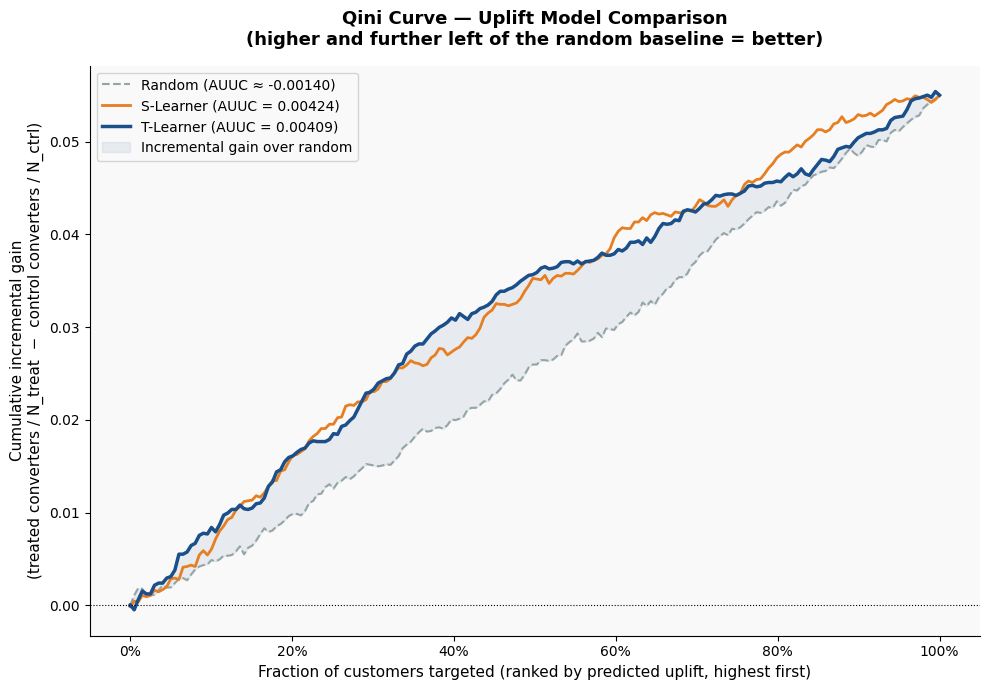

How to read the Qini curve:
- X axis: what fraction of the customer base are we targeting?
- Y axis: how many INCREMENTAL conversions did we generate?
- The random baseline targets customers randomly — no model.
- The gap between our model and the random line is the value
  the model adds. The AUUC measures the size of that gap.


In [6]:
def qini_curve(uplift_scores, outcomes, treatments, n_points=200):
    """
    Calculates the Qini curve for an uplift model.
    Returns proportions (x-axis) and cumulative incremental gains (y-axis).

    At each threshold φ (fraction of customers targeted, ranked by predicted uplift):
      Qini(φ) = n_treat_positive(φ)/N_treat - n_ctrl_positive(φ)/N_ctrl

    The area under this curve (AUUC) is the primary evaluation metric.
    A perfect model scores all Persuadables highest.
    A random model scores customers randomly → diagonal line.
    """
    order = np.argsort(-uplift_scores)
    outcomes_s   = np.array(outcomes)[order]
    treatments_s = np.array(treatments)[order]

    N_treat = treatments_s.sum()
    N_ctrl  = (1 - treatments_s).sum()
    N       = len(uplift_scores)

    indices = np.linspace(0, N - 1, n_points, dtype=int)

    proportions, qini_vals = [0], [0]
    for i in indices:
        top = slice(0, i + 1)
        n_t1 = (outcomes_s[top] * treatments_s[top]).sum()
        n_c1 = (outcomes_s[top] * (1 - treatments_s[top])).sum()
        qini = n_t1 / N_treat - n_c1 / N_ctrl
        proportions.append((i + 1) / N)
        qini_vals.append(qini)

    return np.array(proportions), np.array(qini_vals)


def auuc(proportions, qini_vals):
    """Area Under Uplift Curve — higher is better."""
    random_baseline = np.linspace(0, qini_vals[-1], len(qini_vals))
    return np.trapz(qini_vals - random_baseline, proportions)


# Random baseline (score customers in random order)
np.random.seed(42)
random_scores  = np.random.rand(len(X_test))
prop_rand, qini_rand = qini_curve(random_scores, y_test.values, t_test.values)

# T-Learner
prop_t, qini_t = qini_curve(uplift_t, y_test.values, t_test.values)

# S-Learner
prop_s, qini_s = qini_curve(uplift_s, y_test.values, t_test.values)

auuc_t    = auuc(prop_t, qini_t)
auuc_s    = auuc(prop_s, qini_s)
auuc_rand = auuc(prop_rand, qini_rand)

print(f"AUUC — T-Learner    : {auuc_t:.6f}")
print(f"AUUC — S-Learner    : {auuc_s:.6f}")
print(f"AUUC — Random model : {auuc_rand:.6f}  (≈ 0 by definition)")
print()

fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(prop_rand, qini_rand, color=GREY,   lw=1.5, linestyle='--',
        label=f'Random (AUUC ≈ {auuc_rand:.5f})')
ax.plot(prop_s,    qini_s,    color=ORANGE, lw=2,
        label=f'S-Learner (AUUC = {auuc_s:.5f})')
ax.plot(prop_t,    qini_t,    color=BLUE,   lw=2.5,
        label=f'T-Learner (AUUC = {auuc_t:.5f})')
ax.fill_between(prop_t, qini_rand[:len(prop_t)], qini_t,
                alpha=0.08, color=BLUE, label='Incremental gain over random')

ax.axhline(0, color='black', lw=0.8, linestyle=':')
ax.set_title('Qini Curve — Uplift Model Comparison\n'
             '(higher and further left of the random baseline = better)',
             fontweight='bold', pad=15)
ax.set_xlabel('Fraction of customers targeted (ranked by predicted uplift, highest first)')
ax.set_ylabel('Cumulative incremental gain\n(treated converters / N_treat  −  control converters / N_ctrl)')
ax.legend(fontsize=10)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v*100:.0f}%'))

plt.tight_layout()
plt.savefig(FIGURES / '07_qini_curve.png', dpi=150, bbox_inches='tight')
plt.show()

print("How to read the Qini curve:")
print("- X axis: what fraction of the customer base are we targeting?")
print("- Y axis: how many INCREMENTAL conversions did we generate?")
print("- The random baseline targets customers randomly — no model.")
print("- The gap between our model and the random line is the value")
print("  the model adds. The AUUC measures the size of that gap.")


Uplift by decile (targeting efficiency)

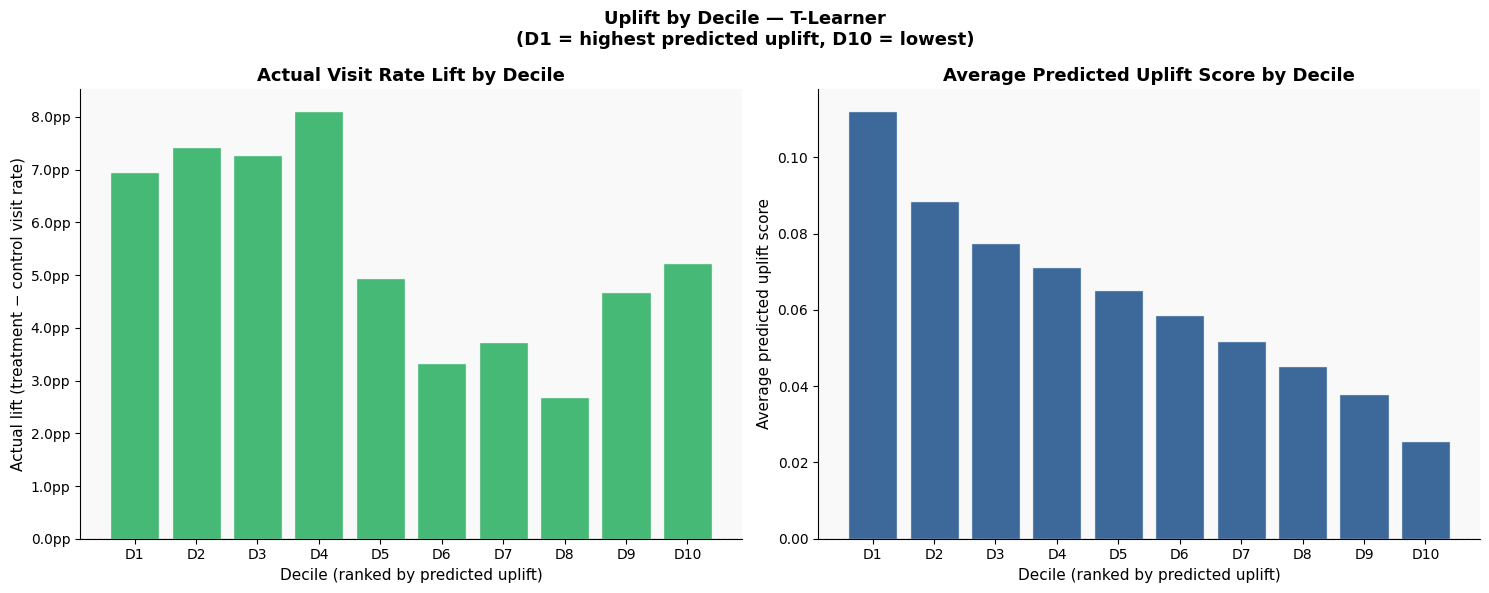


Decile table:
decile_label  n_treat  n_ctrl  treat_visit_rate  ctrl_visit_rate  actual_lift  avg_uplift_score
          D1   1312.0   608.0          0.224085         0.154605     0.069480          0.112283
          D2   1286.0   634.0          0.216174         0.141956     0.074218          0.088598
          D3   1282.0   638.0          0.176287         0.103448     0.072839          0.077419
          D4   1268.0   652.0          0.164038         0.082822     0.081216          0.071314
          D5   1288.0   632.0          0.147516         0.098101     0.049414          0.065308
          D6   1219.0   689.0          0.137818         0.104499     0.033319          0.058740
          D7   1317.0   615.0          0.149582         0.112195     0.037387          0.051952
          D8   1298.0   619.0          0.146379         0.119548     0.026831          0.045260
          D9   1282.0   641.0          0.129485         0.082683     0.046802          0.037980
         D10   1256.0   6

In [7]:
test_df = X_test.copy()
test_df['uplift_t']   = uplift_t
test_df['uplift_s']   = uplift_s
test_df['outcome']    = y_test.values
test_df['treatment']  = t_test.values

# Rank customers into 10 deciles by T-Learner uplift
test_df['decile'] = pd.qcut(test_df['uplift_t'], q=10, labels=False, duplicates='drop')
test_df['decile'] = 9 - test_df['decile']   # flip: decile 0 = highest uplift

decile_stats = (
    test_df.groupby('decile')
    .apply(lambda g: pd.Series({
        'n_treat'         : (g['treatment'] == 1).sum(),
        'n_ctrl'          : (g['treatment'] == 0).sum(),
        'treat_visit_rate': g[g['treatment'] == 1]['outcome'].mean(),
        'ctrl_visit_rate' : g[g['treatment'] == 0]['outcome'].mean(),
        'avg_uplift_score': g['uplift_t'].mean(),
    }))
    .reset_index()
)
decile_stats['actual_lift'] = decile_stats['treat_visit_rate'] - decile_stats['ctrl_visit_rate']
decile_stats['decile_label'] = decile_stats['decile'].apply(lambda x: f'D{x+1}')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Uplift by Decile — T-Learner\n(D1 = highest predicted uplift, D10 = lowest)',
             fontsize=13, fontweight='bold')

colors = [GREEN if v > 0 else RED for v in decile_stats['actual_lift']]
axes[0].bar(decile_stats['decile_label'], decile_stats['actual_lift'],
            color=colors, alpha=0.85, edgecolor='white')
axes[0].axhline(0, color='black', lw=0.8, linestyle='--')
axes[0].set_title('Actual Visit Rate Lift by Decile', fontweight='bold')
axes[0].set_xlabel('Decile (ranked by predicted uplift)')
axes[0].set_ylabel('Actual lift (treatment − control visit rate)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v*100:.1f}pp'))

axes[1].bar(decile_stats['decile_label'], decile_stats['avg_uplift_score'],
            color=BLUE, alpha=0.85, edgecolor='white')
axes[1].axhline(0, color='black', lw=0.8, linestyle='--')
axes[1].set_title('Average Predicted Uplift Score by Decile', fontweight='bold')
axes[1].set_xlabel('Decile (ranked by predicted uplift)')
axes[1].set_ylabel('Average predicted uplift score')

plt.tight_layout()
plt.savefig(FIGURES / '08_uplift_deciles.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nDecile table:")
print(decile_stats[['decile_label', 'n_treat', 'n_ctrl',
                     'treat_visit_rate', 'ctrl_visit_rate',
                     'actual_lift', 'avg_uplift_score']].to_string(index=False))
print()
print("Key insight: the top 2-3 deciles have the highest actual lift.")
print("These are predominantly Persuadable customers.")
print("Targeting only D1-D3 captures most of the incremental value")
print("at a fraction of the total campaign cost.")


Customer response type segmentation

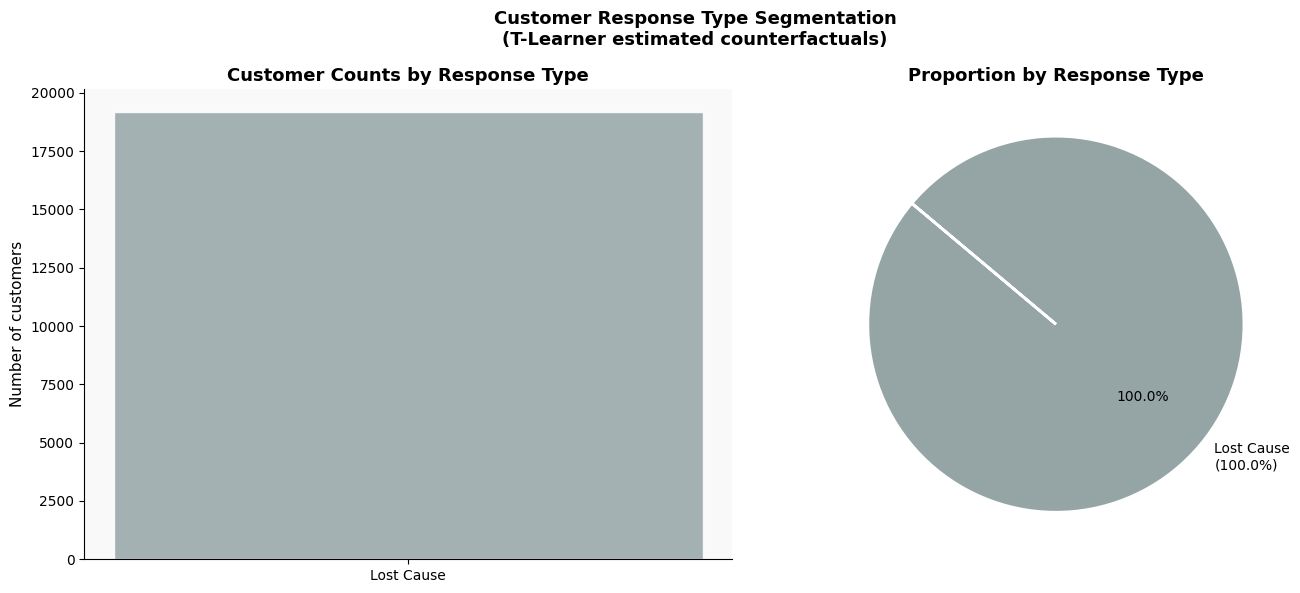

Customer response types:
  Lost Cause     : 19,200  (100.0%)

Business implication:
  Target   : Persuadables only
  Avoid    : Sleeping Dogs (campaign actively harms them)
  Skip     : Sure Things (they buy anyway — wasted spend)
  Ignore   : Lost Causes (no campaign will change their behaviour)


In [8]:
# We can't observe Y(0) and Y(1) for the same person.
# But we CAN approximate response type using predicted probabilities.
#   P(Y=1|T=1) ≈ model_treat.predict(X)
#   P(Y=1|T=0) ≈ model_ctrl.predict(X)

test_df['p_if_treated'] = p_treat_t
test_df['p_if_control'] = p_ctrl_t

THRESH = 0.5   # probability threshold to classify predicted outcome as 1 or 0

test_df['pred_treated'] = (test_df['p_if_treated'] >= THRESH).astype(int)
test_df['pred_control'] = (test_df['p_if_control'] >= THRESH).astype(int)

def classify_response(row):
    t, c = row['pred_treated'], row['pred_control']
    if   t == 1 and c == 0: return 'Persuadable'
    elif t == 1 and c == 1: return 'Sure Thing'
    elif t == 0 and c == 0: return 'Lost Cause'
    else:                   return 'Sleeping Dog'

test_df['response_type'] = test_df.apply(classify_response, axis=1)

type_counts = test_df['response_type'].value_counts()
type_pct    = type_counts / len(test_df) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Customer Response Type Segmentation\n(T-Learner estimated counterfactuals)',
             fontsize=13, fontweight='bold')

type_colors = {
    'Persuadable' : GREEN,
    'Sure Thing'  : BLUE,
    'Lost Cause'  : GREY,
    'Sleeping Dog': RED,
}
order = ['Persuadable', 'Sure Thing', 'Lost Cause', 'Sleeping Dog']
axes[0].bar([t for t in order if t in type_counts.index],
            [type_counts.get(t, 0) for t in order if t in type_counts.index],
            color=[type_colors[t] for t in order if t in type_counts.index],
            alpha=0.85, edgecolor='white')
axes[0].set_title('Customer Counts by Response Type', fontweight='bold')
axes[0].set_ylabel('Number of customers')
axes[0].set_xlabel('')

axes[1].pie(
    [type_counts.get(t, 0) for t in order if t in type_counts.index],
    labels=[f"{t}\n({type_pct.get(t,0):.1f}%)" for t in order if t in type_counts.index],
    colors=[type_colors[t] for t in order if t in type_counts.index],
    autopct='%1.1f%%', startangle=140,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
axes[1].set_title('Proportion by Response Type', fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES / '09_response_types.png', dpi=150, bbox_inches='tight')
plt.show()

print("Customer response types:")
for t in order:
    if t in type_counts.index:
        print(f"  {t:<15}: {type_counts[t]:,}  ({type_pct[t]:.1f}%)")
print()
print("Business implication:")
print("  Target   : Persuadables only")
print("  Avoid    : Sleeping Dogs (campaign actively harms them)")
print("  Skip     : Sure Things (they buy anyway — wasted spend)")
print("  Ignore   : Lost Causes (no campaign will change their behaviour)")


Feature importance for uplift

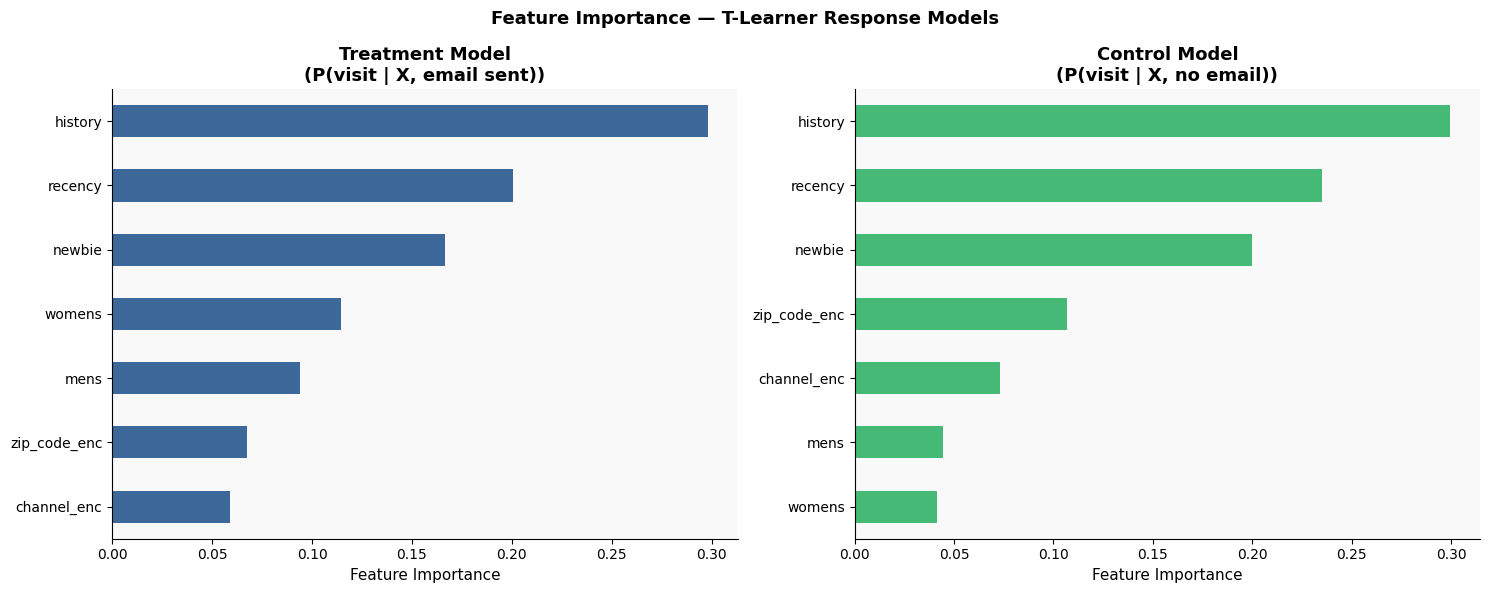

Differences in feature importance (treatment model − control model):
Positive = feature matters MORE when treatment was applied.
Negative = feature matters MORE for organic (no-email) behaviour.

womens          0.073153
mens            0.049457
history        -0.001584
channel_enc    -0.013938
newbie         -0.033426
recency        -0.034607
zip_code_enc   -0.039055


In [9]:
feat_imp_ctrl  = pd.Series(model_ctrl.feature_importances_,  index=FEATURES)
feat_imp_treat = pd.Series(model_treat.feature_importances_, index=FEATURES)
feat_imp_diff  = (feat_imp_treat - feat_imp_ctrl).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Feature Importance — T-Learner Response Models',
             fontsize=13, fontweight='bold')

feat_imp_treat.sort_values().plot(kind='barh', ax=axes[0], color=BLUE, alpha=0.85)
axes[0].set_title('Treatment Model\n(P(visit | X, email sent))', fontweight='bold')
axes[0].set_xlabel('Feature Importance')

feat_imp_ctrl.sort_values().plot(kind='barh', ax=axes[1], color=GREEN, alpha=0.85)
axes[1].set_title('Control Model\n(P(visit | X, no email))', fontweight='bold')
axes[1].set_xlabel('Feature Importance')

plt.tight_layout()
plt.savefig(FIGURES / '10_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print("Differences in feature importance (treatment model − control model):")
print("Positive = feature matters MORE when treatment was applied.")
print("Negative = feature matters MORE for organic (no-email) behaviour.")
print()
print(feat_imp_diff.sort_values(ascending=False).to_string())


Score all customers and save

In [10]:
# Score the FULL dataset (not just test set) for Notebook 04 targeting strategy
X_all = df[FEATURES].copy()

df['p_if_treated']   = model_treat.predict_proba(X_all)[:, 1]
df['p_if_control']   = model_ctrl.predict_proba(X_all)[:, 1]
df['uplift_score']   = df['p_if_treated'] - df['p_if_control']

df['pred_treated']   = (df['p_if_treated'] >= THRESH).astype(int)
df['pred_control']   = (df['p_if_control'] >= THRESH).astype(int)
df['response_type']  = df.apply(classify_response, axis=1)

df['uplift_decile']  = pd.qcut(df['uplift_score'], q=10,
                                labels=[f'D{i}' for i in range(10, 0, -1)],
                                duplicates='drop')

out_path = PROCESSED / 'hillstrom_scored.csv'
df.to_csv(out_path, index=False)
print(f"Saved: {out_path}  ({len(df):,} rows)")
print()
print("New columns added:")
print("  p_if_treated  : P(visit=1) if this customer receives the email")
print("  p_if_control  : P(visit=1) if this customer receives NO email")
print("  uplift_score  : individual causal effect estimate (p_treated - p_ctrl)")
print("  response_type : Persuadable / Sure Thing / Lost Cause / Sleeping Dog")
print("  uplift_decile : D1 = highest predicted uplift, D10 = lowest")
print()
print("Download hillstrom_scored.csv from /content/processed/ before closing Colab.")


Saved: /content/processed/hillstrom_scored.csv  (64,000 rows)

New columns added:
  p_if_treated  : P(visit=1) if this customer receives the email
  p_if_control  : P(visit=1) if this customer receives NO email
  uplift_score  : individual causal effect estimate (p_treated - p_ctrl)
  response_type : Persuadable / Sure Thing / Lost Cause / Sleeping Dog
  uplift_decile : D1 = highest predicted uplift, D10 = lowest

Download hillstrom_scored.csv from /content/processed/ before closing Colab.
